# 01 · EDA de la OBT ECU 911

Predicción de demanda alta a t+3. Se inspecciona el snapshot de Snowflake y se explora solo train para decidir sobre features. La ausencia de datos no se reemplaza por simulaciones.

**Orden:** extraer snapshot una vez con `python -m src.datos snapshot`; luego ejecutar estos cinco notebooks con kernels limpios.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.datos import DATA, DOCS, EVIDENCE
from src.datos import execute
HAS_DATA = (DATA / "obt.parquet").exists()
display(Markdown("**OBT real local disponible**" if HAS_DATA else
    "**PENDIENTE:** faltan credenciales Snowflake válidas y snapshot. Este notebook no contiene resultados empíricos del ECU 911."))


**OBT real local disponible**

## Integridad y disponibilidad

`load_snapshot` verifica SHA256, grain cantón-día, spine diario, medias/lag y targets futuros. El primer año calibra P90; el 20% final se reserva sin inspeccionar distribuciones del hold-out. No se imprimen credenciales.

In [2]:
if HAS_DATA:
    from src.datos import load_snapshot
    obt, snapshot = load_snapshot()
    display(pd.DataFrame([snapshot]))
    print("Tamaño OBT:", obt.shape)
    from src.datos import context
    ctx = context()
    display(pd.DataFrame([ctx["split"]]))
    display(pd.DataFrame([{ "fold": k, "train_rows": len(a), "valid_rows": len(b),
        "train_end": str(ctx["train"].iloc[a].fecha.max()),
        "valid_start": str(ctx["train"].iloc[b].fecha.min()) }
        for k, (a, b) in enumerate(ctx["folds"])]))

,rows,columns,cantones,date_min,date_max,source_table,snapshot_end,query_id,extracted_at,sha256,synthetic
0,429632,37,224,2021-07-01,2026-09-30,ECU911Final.OBT.OBT_EMERGENCIAS_CANTON_DIA,2026-09-30,01c85979-0309-c80e-0000-0012eb7ec0c1,2026-11-11T23:21:57.257842+00:00,1191426ba6930eda1b9334728a41b545acd5a83425afb0...,False


Tamaño OBT: (429632, 37)


2026/11/11 22:50:20 INFO mlflow.tracking.fluent: Experiment with name 'ecu911-alta-demanda' does not exist. Creating a new experiment.


,calibration_end,test_start,embargo_days,n_splits,test_fraction
0,2022-06-30,2025-09-12,7,3,0.2


,fold,train_rows,valid_rows,train_end,valid_start
0,0,63840,64960,2023-04-11 00:00:00,2023-04-19 00:00:00
1,1,128800,64960,2024-01-26 00:00:00,2024-02-03 00:00:00
2,2,193760,64960,2024-11-11 00:00:00,2024-11-19 00:00:00


## Tipos, faltantes, descriptivos, target y outliers

Se registra IQR y |Z|≥3; no se eliminan automáticamente los picos que queremos anticipar. Spearman mide asociación monótona con conteos asimétricos. El target binario también se analiza mediante prevalencia para t+3.

Perfil estructural de la OBT completa (incluye bordes con ventanas/targets incompletos):


,Unnamed: 0,dtype,nulls,missing_fraction
0,cod_canton,str,0,0.000000
1,fecha,datetime64[ms],0,0.000000
2,canton,str,0,0.000000
3,cod_provincia,str,0,0.000000
4,provincia,str,0,0.000000
5,region,str,0,0.000000
6,es_zona_no_delimitada,bool,0,0.000000
7,anio,int16,0,0.000000
8,trimestre,int8,0,0.000000
9,mes,int8,0,0.000000


Perfil del bloque de entrenamiento utilizado en EDA y modelado:


,Unnamed: 0,dtype,nulls,missing_fraction
0,cod_canton,str,0,0.000000
1,fecha,datetime64[ms],0,0.000000
2,canton,str,0,0.000000
3,cod_provincia,str,0,0.000000
4,provincia,str,0,0.000000
5,region,str,0,0.000000
6,es_zona_no_delimitada,bool,0,0.000000
7,anio,int16,0,0.000000
8,trimestre,int8,0,0.000000
9,mes,int8,0,0.000000


,Unnamed: 0,cod_canton,fecha,canton,cod_provincia,provincia,region,es_zona_no_delimitada,anio,trimestre,...,n_sin_servicio,lag_1d,lag_7d,lag_14d,lag_28d,media_prev_7d,media_prev_28d,es_feriado_t3,obj_n_emergencias_t3,seasonal_t3
0,count,260288.0,260288,260288,260288.0,260288,260288,260288,260288.000000,260288.000000,...,260288.000000,260288.000000,260288.000000,260288.000000,260288.000000,260288.000000,260288.000000,260288,260288.000000,260288.000000
1,unique,224.0,NaN,222,25.0,25,5,2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
2,top,101.0,NaN,BOLIVAR,9.0,GUAYAS,Sierra,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
3,freq,1162.0,NaN,2324,29050.0,29050,105742,257964,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,250880,NaN,NaN
4,mean,NaN,2024-02-01 12:00:00,NaN,NaN,NaN,NaN,NaN,2023.581756,2.536145,...,0.008329,41.157479,41.145420,41.174357,41.262087,41.152171,41.186532,NaN,41.153311,41.184945
5,min,NaN,2022-07-01 00:00:00,NaN,NaN,NaN,NaN,NaN,2022.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.071400,NaN,0.000000,0.000000
6,25%,NaN,2023-04-17 00:00:00,NaN,NaN,NaN,NaN,NaN,2023.000000,2.000000,...,0.000000,3.000000,3.000000,3.000000,3.000000,3.571400,3.714300,NaN,3.000000,3.500000
7,50%,NaN,2024-02-01 12:00:00,NaN,NaN,NaN,NaN,NaN,2024.000000,3.000000,...,0.000000,8.000000,8.000000,8.000000,8.000000,7.571400,7.571400,NaN,8.000000,7.750000
8,75%,NaN,2024-11-18 00:00:00,NaN,NaN,NaN,NaN,NaN,2024.000000,3.000000,...,0.000000,22.000000,22.000000,22.000000,22.000000,22.142900,22.107100,NaN,22.000000,21.750000
9,max,NaN,2025-09-04 00:00:00,NaN,NaN,NaN,NaN,NaN,2025.000000,4.000000,...,244.000000,3070.000000,3070.000000,3097.000000,3097.000000,2444.428600,2303.285700,NaN,3070.000000,2839.250000


,Unnamed: 0,iqr_count,z_ge_3_count
0,anio,0,0
1,trimestre,0,0
2,mes,0,0
3,dia_mes,0,0
4,dia_semana,0,0
5,n_emergencias,32267,2415
6,n_seguridad_ciudadana,31557,2324
7,n_gestion_sanitaria,19831,3069
8,n_transito_movilidad,29133,3098
9,n_servicios_municipales,34264,2201


3    0.082132
Name: fracción alta demanda, dtype: float64

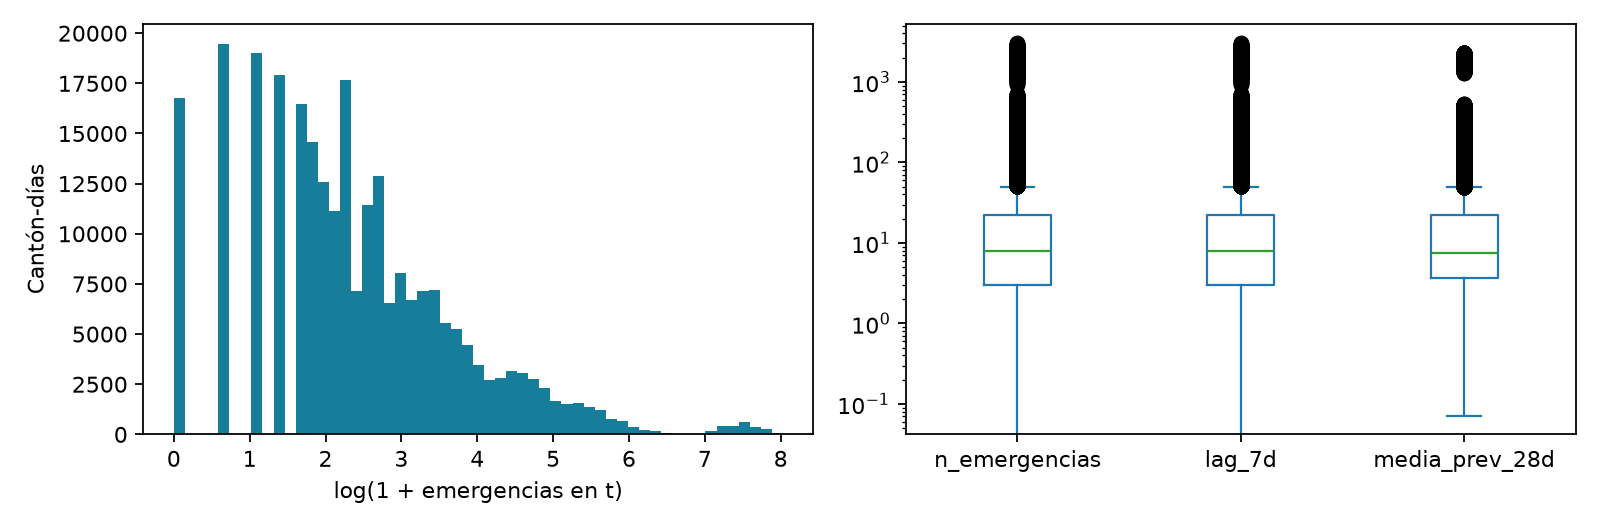

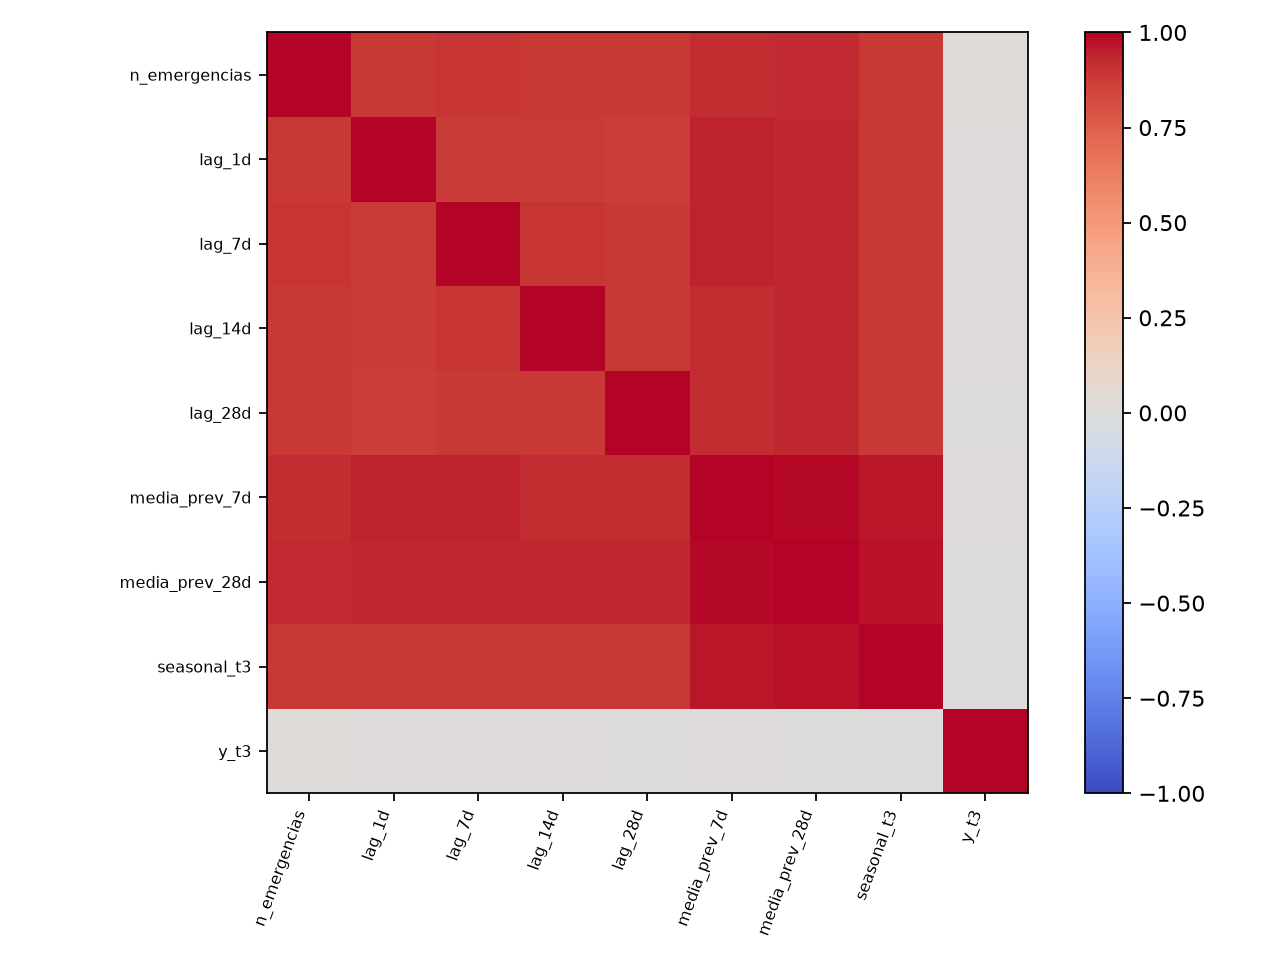

In [3]:
if HAS_DATA:
    eda = execute("eda")
    print("Perfil estructural de la OBT completa (incluye bordes con ventanas/targets incompletos):")
    display(pd.read_csv(EVIDENCE / "eda/snapshot_schema.csv"))
    print("Perfil del bloque de entrenamiento utilizado en EDA y modelado:")
    display(pd.read_csv(EVIDENCE / "eda/schema.csv"))
    display(pd.read_csv(EVIDENCE / "eda/descriptive.csv"))
    display(pd.read_csv(EVIDENCE / "eda/outliers.csv"))
    display(pd.Series(eda["prevalence"], name="fracción alta demanda"))
    display(Image(filename=str(EVIDENCE / "eda/distribucion_boxplot.png")))
    display(Image(filename=str(EVIDENCE / "eda/correlacion.png")))

## Hallazgos que cambian el modelado

La tabla se genera con evidencia real de train; hasta entonces no se afirma que se hayan observado tres hallazgos. Anomalía enero 2024 documentada por PSet 2: se conserva y su marca no se ofrece al modelo.

In [4]:
if HAS_DATA:
    display(pd.read_csv(EVIDENCE / "eda/hallazgos.csv"))
else:
    display(Markdown("Pendiente: completar EDA con la OBT real y revisar sus consecuencias antes de entrenar."))

,hallazgo,evidencia,consecuencia
0,Escalas cantonales y cola del volumen,asimetría=9.913; ceros=6.45%; IQR flags=32267,Usar Spearman y ratios de tendencia/cambio; no...
1,Heterogeneidad cantonal,"media cantonal P10=1.770, P90=68.391","Escalado dentro de fold, features relativas y ..."
2,Distribución real de alta demanda,prevalencia train t+3=8.21%,Comparar AP (PR-AUC no interpolada); calibrar ...
3,Patrón semanal observado,"medias por weekday: {0: 37.82, 1: 35.27, 2: 36...",Incluir sin/cos del día objetivo y media de cu...
